# 03 · Models: linear regression and XGBoost

We predict ln(1 + worldwide revenue in 2025 dollars) from pre-release information, and measure how much the cast, crew and text features add.

| Model | Features |
|---|---|
| **Baseline** | structured features only: budget, runtime, release date, genres, language, country, counts, sequel flag |
| **Full** | baseline + cast and crew track record + plot embedding + keyword embedding |

Each model is fitted with linear regression and with XGBoost. We also add the three groups one at a time to see which of them carry the improvement. Our goal is a 20% lower error than the linear baseline.

1. Imports
2. Load
3. Feature sets
4. Cross-validation
5. Results
6. Feature importance
7. Test set

## 1. Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid", context="notebook")

## 2. Load

In [2]:
feat = pd.read_parquet("features.parquet")
print(feat.shape)
feat["split"].value_counts()

(6090, 130)


split
train    4263
test      914
val       913
Name: count, dtype: int64

## 3. Feature sets

The feature groups are identified by their column names, as built in notebook 02.

In [3]:
id_cols = ["imdb_id", "title", "split", "log_revenue_cpi", "revenue_cpi"]
track = [c for c in feat if c.startswith(("exp_", "prev_rev_"))]
plot = [c for c in feat if c.startswith("plot_emb_")]
keyword = [c for c in feat if c.startswith("kw_emb_")]
structured = [c for c in feat if c not in id_cols + track + plot + keyword]

feature_sets = {
    "baseline": structured,
    "+ track record": structured + track,
    "+ plot emb": structured + plot,
    "+ keyword emb": structured + keyword,
    "full": structured + track + plot + keyword,
}
pd.Series({k: len(v) for k, v in feature_sets.items()}, name="features")

baseline           47
+ track record     61
+ plot emb         79
+ keyword emb      79
full              125
Name: features, dtype: int64

In [4]:
pd.Series({
    "structured": structured,
    "track record": track,
    "plot embedding": f"{plot[0]} … {plot[-1]}",
    "keyword embedding": f"{keyword[0]} … {keyword[-1]}",
}, name="columns").to_frame()

,columns
structured,"[log_budget_cpi, runtime, year, month, weekday..."
track record,"[exp_actor, prev_rev_actor, exp_director, prev..."
plot embedding,plot_emb_0 … plot_emb_31
keyword embedding,kw_emb_0 … kw_emb_31


## 4. Cross-validation

We compare models with **5-fold cross-validation on the train and validation films together**, and report the mean and standard deviation over the folds. A single validation split is too noisy to separate feature sets whose errors differ by a few hundredths.

- **Linear regression:** missing values filled with the median of the training folds (plus an indicator column marking them), features standardised.
- **XGBoost:** the same hyperparameters for every feature set. Inside each fold, 15% of the training films decide when to stop adding trees.

The test films are not used until section 7.

In [5]:
y = feat["log_revenue_cpi"]
dev = feat["split"].isin(["train", "val"])
te = feat["split"] == "test"
print(f"cross-validation films: {dev.sum():,}   test films: {te.sum():,}")


def scores(y_true, y_pred):
    return {"RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
            "MAE": mean_absolute_error(y_true, y_pred),
            "R2": r2_score(y_true, y_pred)}


def fit_linear(X, y_):
    return make_pipeline(SimpleImputer(strategy="median", add_indicator=True),
                         StandardScaler(), LinearRegression()).fit(X, y_)


XGB_PARAMS = dict(
    n_estimators=3000,
    learning_rate=0.03,
    max_depth=5,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    early_stopping_rounds=100,
    eval_metric="rmse",
    random_state=42,
)


def fit_xgb(X, y_):
    X_fit, X_stop, y_fit, y_stop = train_test_split(X, y_, test_size=0.15, random_state=42)
    return xgb.XGBRegressor(**XGB_PARAMS).fit(X_fit, y_fit, eval_set=[(X_stop, y_stop)], verbose=False)


runs = {
    "Linear: baseline": (fit_linear, "baseline"),
    "Linear: full": (fit_linear, "full"),
    "XGBoost: baseline": (fit_xgb, "baseline"),
    "XGBoost: + track record": (fit_xgb, "+ track record"),
    "XGBoost: + plot emb": (fit_xgb, "+ plot emb"),
    "XGBoost: + keyword emb": (fit_xgb, "+ keyword emb"),
    "XGBoost: full": (fit_xgb, "full"),
}

cross-validation films: 5,176   test films: 914


In [6]:
X_dev, y_dev = feat.loc[dev], y[dev]
folds = list(KFold(n_splits=5, shuffle=True, random_state=42).split(X_dev))

rows = []
for run, (fit, fs) in runs.items():
    cols = feature_sets[fs]
    for k, (i_tr, i_va) in enumerate(folds):
        model = fit(X_dev.iloc[i_tr][cols], y_dev.iloc[i_tr])
        rows.append({"run": run, "fold": k, **scores(y_dev.iloc[i_va], model.predict(X_dev.iloc[i_va][cols]))})

fold_scores = pd.DataFrame(rows)

## 5. Results

In [7]:
summary = fold_scores.groupby("run", sort=False)[["RMSE", "MAE", "R2"]].agg(["mean", "std"])
lin_rmse = summary.loc["Linear: baseline", ("RMSE", "mean")]
summary[("RMSE vs linear baseline", "")] = (1 - summary[("RMSE", "mean")] / lin_rmse).map("{:+.1%}".format)
summary.round(3)

RMSE           MAE            R2         \
                          mean    std   mean    std   mean    std   
run                                                                 
Linear: baseline         1.553  0.010  1.176  0.009  0.530  0.015   
Linear: full             1.438  0.008  1.090  0.005  0.597  0.014   
XGBoost: baseline        1.435  0.009  1.074  0.008  0.598  0.018   
XGBoost: + track record  1.372  0.012  1.029  0.006  0.633  0.015   
XGBoost: + plot emb      1.453  0.015  1.092  0.015  0.588  0.021   
XGBoost: + keyword emb   1.431  0.018  1.076  0.014  0.601  0.023   
XGBoost: full            1.369  0.015  1.026  0.011  0.635  0.017   

                        RMSE vs linear baseline  
                                                 
run                                              
Linear: baseline                          +0.0%  
Linear: full                              +7.4%  
XGBoost: baseline                         +7.6%  
XGBoost: + track record                  +11.7%  
XGBoost: + plot emb                       +6.4%  
XGBoost: + keyword emb                    +7.9%  
XGBoost: full                            +11.8%

Scores are in units of ln(revenue), averaged over 5 folds (± one standard deviation). An RMSE of 1.0 means a typical prediction is off by a factor of about e ≈ 2.7. `RMSE vs linear baseline` is the reduction in RMSE; our goal is +20%.

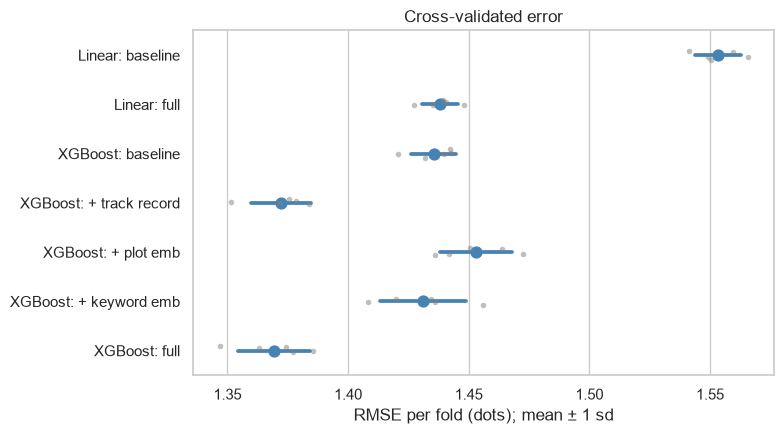

In [8]:
fig, ax = plt.subplots(figsize=(8, 4.5))
order = list(runs)
sns.pointplot(data=fold_scores, y="run", x="RMSE", order=order, errorbar="sd",
              linestyles="none", color="steelblue", ax=ax)
sns.stripplot(data=fold_scores, y="run", x="RMSE", order=order, color="gray", alpha=0.5, size=4, ax=ax)
ax.set_ylabel("")
ax.set_xlabel("RMSE per fold (dots); mean ± 1 sd")
ax.set_title("Cross-validated error")
plt.tight_layout()

**Paired comparison with the XGBoost baseline.** All runs use the same folds, so we compare them fold by fold; a negative difference means lower error than the baseline.

In [9]:
wide = fold_scores.pivot(index="fold", columns="run", values="RMSE")
others = [r for r in runs if r.startswith("XGBoost") and r != "XGBoost: baseline"]
diff = wide[others].sub(wide["XGBoost: baseline"], axis=0)
diff.agg(["mean", "std", "min", "max"]).T.round(3).assign(folds_improved=(diff < 0).sum().astype(str) + " / 5")

,mean,std,min,max,folds_improved
run,,,,,
XGBoost: + track record,-0.063,0.006,-0.069,-0.057,5 / 5
XGBoost: + plot emb,0.018,0.010,0.004,0.030,0 / 5
XGBoost: + keyword emb,-0.004,0.013,-0.023,0.013,4 / 5
XGBoost: full,-0.066,0.010,-0.080,-0.057,5 / 5


## 6. Feature importance

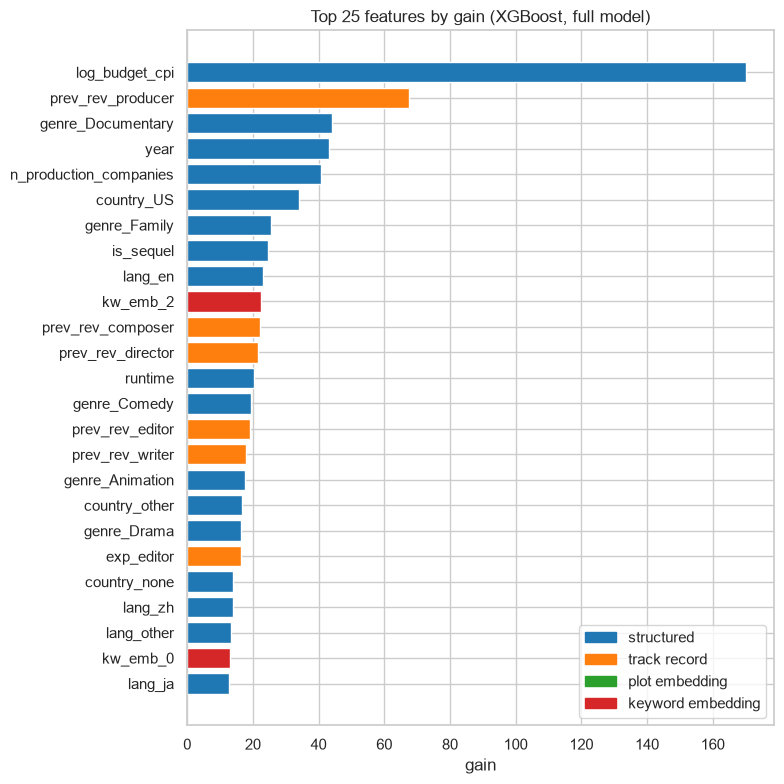

In [10]:
xgb_full = fit_xgb(X_dev[feature_sets["full"]], y_dev)
imp = pd.Series(xgb_full.get_booster().get_score(importance_type="gain")).sort_values(ascending=False)

group_of = {c: g for g, cols in [("structured", structured), ("track record", track),
                                ("plot embedding", plot), ("keyword embedding", keyword)] for c in cols}
top = imp.head(25)
palette = dict(zip(["structured", "track record", "plot embedding", "keyword embedding"], sns.color_palette("tab10", 4)))

fig, ax = plt.subplots(figsize=(8, 8))
ax.barh(top.index[::-1], top.values[::-1], color=[palette[group_of[c]] for c in top.index[::-1]])
ax.set_xlabel("gain")
ax.set_title("Top 25 features by gain (XGBoost, full model)")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in palette.values()], labels=list(palette), loc="lower right")
plt.tight_layout()

In [11]:
imp.groupby(imp.index.map(group_of)).sum().div(imp.sum()).sort_values(ascending=False).map("{:.0%}".format).rename("share of total gain")

structured           52%
keyword embedding    18%
track record         15%
plot embedding       15%
Name: share of total gain, dtype: str

## 7. Test set

Each model is refitted on all cross-validation films and scored once on the held-out test films.

In [12]:
test_scores, test_preds = {}, {}
for run, (fit, fs) in runs.items():
    cols = feature_sets[fs]
    model = fit(X_dev[cols], y_dev)
    test_preds[run] = model.predict(feat.loc[te, cols])
    test_scores[run] = scores(y[te], test_preds[run])

test_res = pd.DataFrame(test_scores).T
test_res["RMSE vs linear baseline"] = (1 - test_res["RMSE"] / test_res.loc["Linear: baseline", "RMSE"]).map("{:+.1%}".format)
test_res.round(3)

,RMSE,MAE,R2,RMSE vs linear baseline
Linear: baseline,1.552,1.160,0.522,+0.0%
Linear: full,1.462,1.107,0.575,+5.8%
XGBoost: baseline,1.406,1.062,0.607,+9.4%
XGBoost: + track record,1.361,1.017,0.632,+12.3%
XGBoost: + plot emb,1.448,1.090,0.584,+6.7%
XGBoost: + keyword emb,1.383,1.061,0.620,+10.9%
XGBoost: full,1.350,1.014,0.638,+13.0%


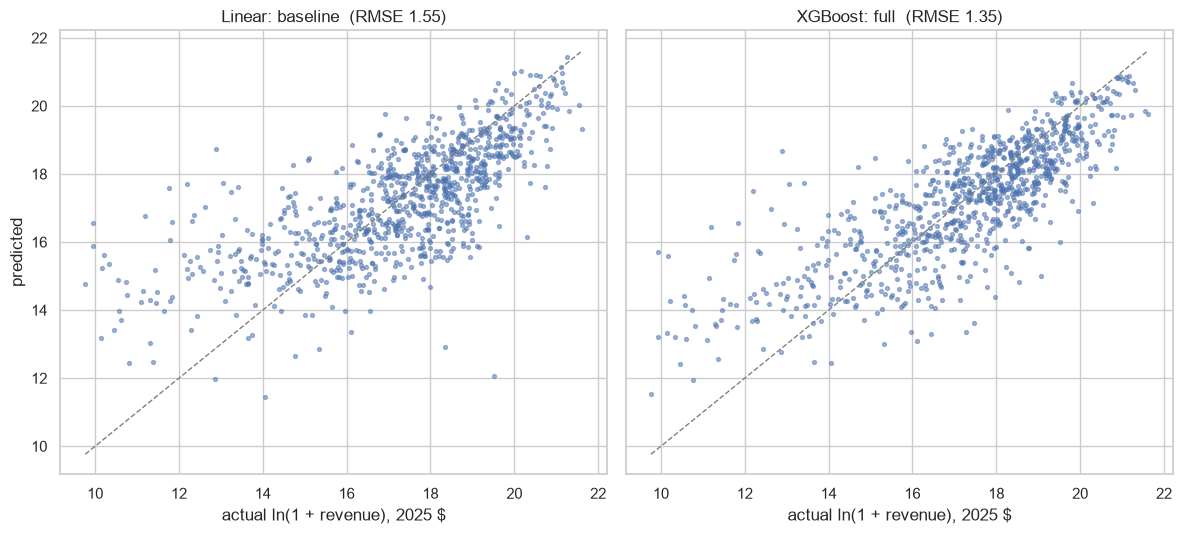

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), sharex=True, sharey=True)
for ax, run in zip(axes, ["Linear: baseline", "XGBoost: full"]):
    pred = test_preds[run]
    ax.scatter(y[te], pred, s=8, alpha=0.5)
    lims = [y[te].min(), y[te].max()]
    ax.plot(lims, lims, color="gray", ls="--", lw=1)
    ax.set_title(f"{run}  (RMSE {test_scores[run]['RMSE']:.2f})")
    ax.set_xlabel("actual ln(1 + revenue), 2025 $")
axes[0].set_ylabel("predicted")
plt.tight_layout()